# Comparação direta Brasil × CBIS-DDSM: densidade mamária e BI-RADS

Com os laudos do **SISCAN** (`python -m src.scraping.siscan`), passa a ser possível comparar diretamente as duas
variáveis clínicas que o CBIS-DDSM tem e o Brasil publica:

1. **Densidade mamária:** a distribuição é a mesma? E como ela muda com a idade?
2. **BI-RADS:** que tipo de caso cada base contém?
3. **Desempenho do modelo na composição brasileira:** usando as previsões do modelo de imagens
   (`03_imagens_calcificacoes.ipynb`), qual seria a AUC se os casos tivessem a distribuição de densidade do Brasil,
   no geral e por faixa etária?

**Correspondência de escalas:** o laudo do SISCAN informa o *tipo de mama*, que corresponde às categorias de
densidade do BI-RADS usadas no CBIS-DDSM: Adiposa = 1, Predominantemente adiposa = 2, Predominantemente densa = 3,
Densa = 4.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src import config
from src.processing.cbis import carrega_cbis
from src.visualization import estilo
from src.visualization.estilo import AZUL, LARANJA, VERDE_AGUA, salvar

estilo.aplicar()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

I = config.INTERIM
sis = {n: pd.read_csv(I / f"siscan_{n}.csv") for n in
       ["densidade_ano", "densidade_faixa", "densidade_indicacao", "birads_indicacao", "birads_densidade"]}
cbis = carrega_cbis()
cbis["breast_density"] = cbis["breast_density"].replace(0, np.nan)
pred = pd.read_csv(config.PROCESSED / "cbis_predicoes_teste_calcificacoes.csv")

DENS = [1, 2, 3, 4]
NOMES_DENS = {1: "1 adiposa", 2: "2 pred. adiposa", 3: "3 pred. densa", 4: "4 densa"}

def distribuicao(contagens):
    s = pd.Series(contagens).reindex(DENS).fillna(0)
    return 100 * s / s.sum()

## 1. Densidade mamária: Brasil × CBIS-DDSM

Brasil: laudos do SISCAN de mulheres, 2018–2022 (mama direita; a esquerda é praticamente igual, ver
`docs/scraping_siscan.md`). CBIS-DDSM: todas as lesões, e separado por tipo de lesão.

Com milhões de exames, qualquer diferença daria "p < 0,001" num qui-quadrado. Por isso medimos o **tamanho** da
diferença:

- **w de Cohen:** 0,1 pequena, 0,3 média, 0,5 grande;
- **distância de variação total (DVT):** a porcentagem dos casos que precisaria "mudar de categoria" para as duas
  distribuições ficarem iguais.

In [2]:
br_dens = distribuicao(sis["densidade_ano"].dropna(subset=["densidade_birads_linha"])
                       .groupby("densidade_birads_linha")["exames"].sum())

def diferenca(p, q):
    p, q = p / 100, q / 100
    return {"w de Cohen": float(np.sqrt((((p - q) ** 2) / q).sum())), "DVT (%)": float(50 * (p - q).abs().sum())}

densidades = pd.DataFrame({
    "Brasil (SISCAN)": br_dens,
    "CBIS: todas as lesões": distribuicao(cbis["breast_density"].value_counts()),
    "CBIS: massas": distribuicao(cbis.query("abnormality_type == 'mass'")["breast_density"].value_counts()),
    "CBIS: calcificações": distribuicao(cbis.query("abnormality_type == 'calcification'")["breast_density"].value_counts()),
    "CBIS: teste do modelo": distribuicao(pred["breast_density"].value_counts()),
}).rename(index=NOMES_DENS)
display(densidades.round(1))

pd.DataFrame({c: diferenca(densidades[c], densidades["Brasil (SISCAN)"]) for c in densidades.columns[1:]}).T.round(3)

,Brasil (SISCAN),CBIS: todas as lesões,CBIS: massas,CBIS: calcificações,CBIS: teste do modelo
1 adiposa,15.70,15.00,19.90,10.60,7.40
2 pred. adiposa,34.10,38.50,44.60,32.90,35.50
3 pred. densa,34.20,30.90,26.50,35.00,35.50
4 densa,16.00,15.50,9.00,21.40,21.60


,w de Cohen,DVT (%)
CBIS: todas as lesões,0.10,4.43
CBIS: massas,0.30,14.71
CBIS: calcificações,0.19,6.21
CBIS: teste do modelo,0.26,8.31


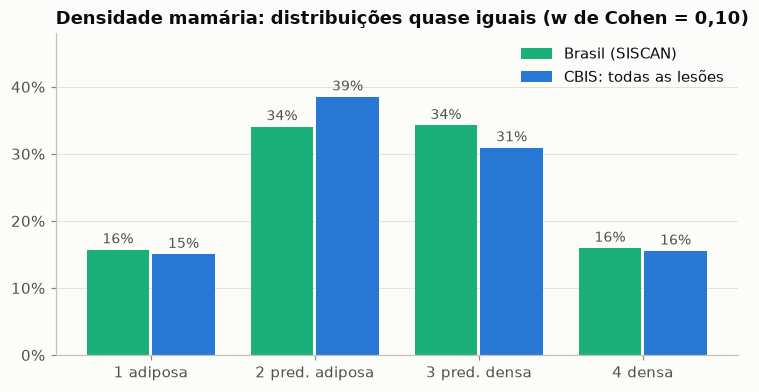

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(4)
larg = 0.38
for i, (col, cor) in enumerate([("Brasil (SISCAN)", VERDE_AGUA), ("CBIS: todas as lesões", AZUL)]):
    barras = ax.bar(x + (i - 0.5) * (larg + 0.02), densidades[col], larg, color=cor, label=col)
    ax.bar_label(barras, fmt="%.0f%%", padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
ax.set_xticks(x, densidades.index)
ax.set_ylim(0, 48)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.legend(loc="upper right")
w = diferenca(densidades["CBIS: todas as lesões"], densidades["Brasil (SISCAN)"])["w de Cohen"]
ax.set_title(f"Densidade mamária: distribuições quase iguais (w de Cohen = {w:.2f})".replace(".", ","))
salvar(fig, "15_densidade_brasil_cbis")

### 1.1 Mas a densidade depende muito da idade

No Brasil, a proporção de mamas densas (categorias 3 e 4) por faixa etária. A linha tracejada é a proporção de
mamas densas do CBIS-DDSM, que não informa a idade das pacientes.

In [4]:
fx = sis["densidade_faixa"].dropna(subset=["densidade_birads_linha"])
fx = fx[~fx["coluna"].isin(["Ignorado"])]
ordem_faixas = list(dict.fromkeys(fx["coluna"]))
tab_fx = fx.pivot_table(index="coluna", columns="densidade_birads_linha", values="exames", aggfunc="sum").reindex(ordem_faixas)
tab_fx_pct = 100 * tab_fx.div(tab_fx.sum(axis=1), axis=0)
tab_fx_pct["% densas (3+4)"] = tab_fx_pct[3] + tab_fx_pct[4]
tab_fx_pct["exames"] = tab_fx.sum(axis=1)

def rotulo_faixa(f):
    return (f.replace("Entre ", "").replace(" anos", "").replace(" a ", "–")
             .replace("Acima de 79", "80+").replace("Até 9", "≤9"))

tab_fx_pct.index = [rotulo_faixa(f) for f in tab_fx_pct.index]
tab_fx_pct.round(1)

densidade_birads_linha,1.00,2.00,3.00,4.00,% densas (3+4),exames
≤9,15.00,33.90,35.10,16.00,51.00,"2,102.00"
10–14,9.10,20.10,41.40,29.40,70.80,507.00
15–19,5.00,9.00,37.00,48.90,86.00,"3,261.00"
20–24,6.30,11.20,38.90,43.60,82.50,"9,629.00"
25–29,7.80,14.40,42.30,35.50,77.90,"20,292.00"
30–34,8.70,18.00,43.90,29.30,73.30,"56,986.00"
35–39,9.00,20.90,43.90,26.20,70.20,"285,023.00"
40–44,9.20,22.70,43.70,24.40,68.10,"1,605,179.00"
45–49,10.70,25.80,42.10,21.40,63.50,"2,025,009.00"
50–54,14.50,33.00,36.10,16.30,52.40,"2,787,921.00"


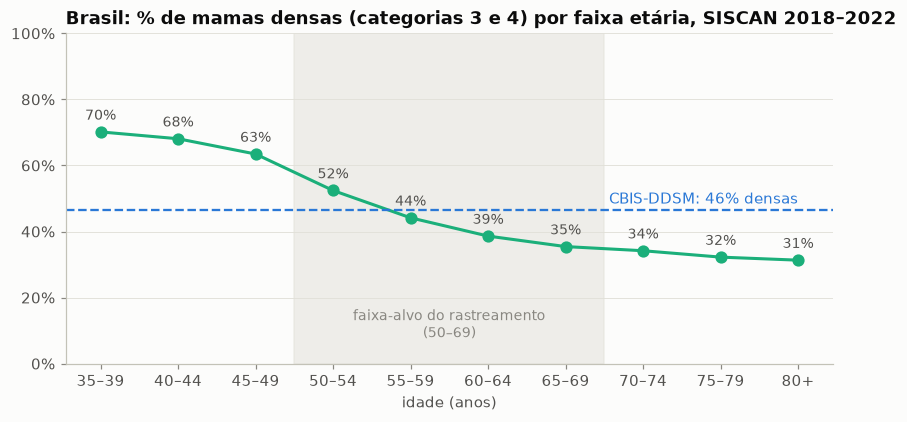

In [5]:
mostrar = tab_fx_pct.loc["35–39":"80+"]
cbis_densas = densidades.loc[["3 pred. densa", "4 densa"], "CBIS: todas as lesões"].sum()

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.plot(mostrar.index, mostrar["% densas (3+4)"], marker="o", markersize=7, color=VERDE_AGUA)
for xi, yi in zip(mostrar.index, mostrar["% densas (3+4)"]):
    ax.annotate(f"{yi:.0f}%", (xi, yi), xytext=(0, 8), textcoords="offset points", ha="center",
                color=estilo.TINTA_SECUNDARIA, fontsize=9)
ax.axhline(cbis_densas, color=AZUL, ls="--", lw=1.5)
ax.text(len(mostrar) - 1, cbis_densas + 2, f"CBIS-DDSM: {cbis_densas:.0f}% densas", color=AZUL, ha="right", fontsize=9.5)
ax.axvspan(3 - 0.5, 6 + 0.5, color=estilo.GRADE, alpha=0.5, zorder=0)
ax.text(4.5, 8, "faixa-alvo do rastreamento\n(50–69)", ha="center", color=estilo.TINTA_SUAVE, fontsize=9)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("idade (anos)")
ax.set_title("Brasil: % de mamas densas (categorias 3 e 4) por faixa etária, SISCAN 2018–2022")
salvar(fig, "16_densidade_por_idade")

## 2. BI-RADS: que tipo de caso cada base contém

A categoria 6 (câncer já confirmado por biópsia) existe no SISCAN, mas não no CBIS-DDSM. Por isso, as distribuições
abaixo usam só as categorias 0 a 5. O SISCAN separa a mamografia de **rastreamento** (mulheres sem sintomas) da
**diagnóstica** (investigação de alteração).

In [6]:
bi = sis["birads_indicacao"]
bi = bi[bi["linha"].str.match(r"Categoria [0-5]$")].copy()
bi["birads"] = bi["linha"].str.extract(r"(\d)").astype(int)
br_bi = bi.pivot_table(index="birads", columns="coluna", values="exames", aggfunc="sum")
cbis_bi = cbis["assessment"].value_counts().reindex(range(6)).fillna(0)

birads = pd.DataFrame({
    "Brasil: rastreamento": 100 * br_bi["Mamog. Rastreamento"] / br_bi["Mamog. Rastreamento"].sum(),
    "Brasil: diagnóstica": 100 * br_bi["Mamog. Diagnostica"] / br_bi["Mamog. Diagnostica"].sum(),
    "CBIS-DDSM": 100 * cbis_bi / cbis_bi.sum(),
})
birads.index = [f"BI-RADS {i}" for i in birads.index]
birads.loc["suspeitos (4 + 5)"] = birads.loc[["BI-RADS 4", "BI-RADS 5"]].sum()
display(birads.round(2))
print("Exames no SISCAN (0–5):", br_bi.sum().astype(int).to_dict())

,Brasil: rastreamento,Brasil: diagnóstica,CBIS-DDSM
BI-RADS 0,11.59,15.29,6.67
BI-RADS 1,34.02,21.94,0.08
BI-RADS 2,51.55,42.43,18.05
BI-RADS 3,1.95,15.20,13.37
BI-RADS 4,0.76,4.09,45.77
BI-RADS 5,0.13,1.04,16.06
suspeitos (4 + 5),0.89,5.12,61.83


Exames no SISCAN (0–5): {'Mamog. Diagnostica': 303806, 'Mamog. Rastreamento': 13117293}


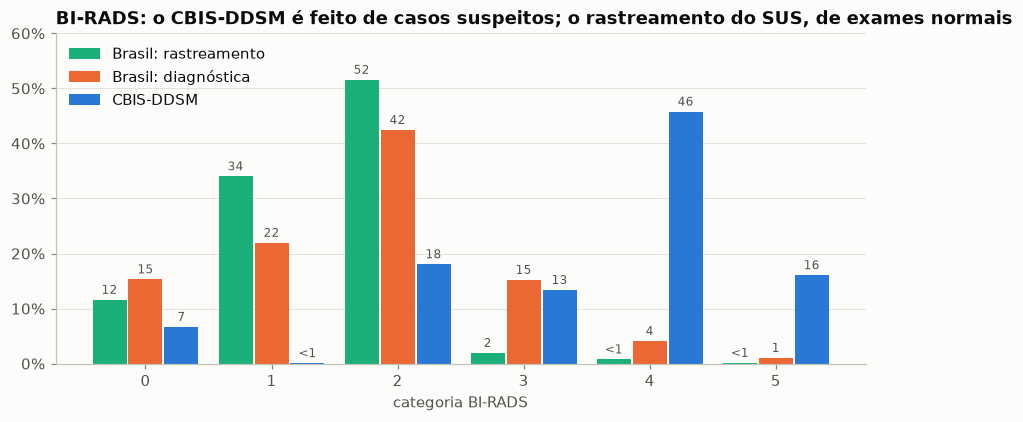

In [7]:
plot_bi = birads.iloc[:6]
fig, ax = plt.subplots(figsize=(9.5, 3.9))
x = np.arange(6)
larg = 0.27
series = [("Brasil: rastreamento", VERDE_AGUA), ("Brasil: diagnóstica", LARANJA), ("CBIS-DDSM", AZUL)]
for i, (col, cor) in enumerate(series):
    barras = ax.bar(x + (i - 1) * (larg + 0.015), plot_bi[col], larg, color=cor, label=col)
    ax.bar_label(barras, labels=[f"{v:.0f}" if v >= 1 else "<1" for v in plot_bi[col]], padding=2,
                 color=estilo.TINTA_SECUNDARIA, fontsize=8)
ax.set_xticks(x, [str(i) for i in range(6)])
ax.set_xlabel("categoria BI-RADS")
ax.set_ylim(0, 60)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.legend(loc="upper left")
ax.set_title("BI-RADS: o CBIS-DDSM é feito de casos suspeitos; o rastreamento do SUS, de exames normais")
salvar(fig, "17_birads_brasil_cbis")

## 3. Densidade × dificuldade: o que o Brasil e o modelo mostram

Duas evidências independentes de que **mamas densas são mais difíceis**:

- **Brasil (SISCAN):** proporção de laudos **BI-RADS 0** (inconclusivo, precisa de exames complementares) por densidade;
- **CBIS-DDSM:** AUC do modelo de imagens por densidade (notebook 03).

In [8]:
bd = sis["birads_densidade"].dropna(subset=["densidade_birads_coluna"])
bd = bd[bd["linha"].str.match(r"Categoria [0-5]$")]
tab_bd = bd.pivot_table(index="densidade_birads_coluna", columns="linha", values="exames", aggfunc="sum")
inconclusivo = 100 * tab_bd["Categoria 0"] / tab_bd.sum(axis=1)
suspeito = 100 * (tab_bd["Categoria 4"] + tab_bd["Categoria 5"]) / tab_bd.sum(axis=1)

auc_dens = {int(d): roc_auc_score(g["maligno"], g["prob"]) for d, g in pred.dropna(subset=["breast_density"]).groupby("breast_density")}
dificuldade = pd.DataFrame({"Brasil: % BI-RADS 0": inconclusivo, "Brasil: % BI-RADS 4–5": suspeito,
                            "CBIS: AUC do modelo": pd.Series(auc_dens),
                            "CBIS: n no teste": pred["breast_density"].value_counts()}).rename(index=NOMES_DENS)
dificuldade

,Brasil: % BI-RADS 0,Brasil: % BI-RADS 4–5,CBIS: AUC do modelo,CBIS: n no teste
1 adiposa,7.74,0.71,1.00,24
2 pred. adiposa,10.84,0.90,0.85,115
3 pred. densa,14.15,1.14,0.71,115
4 densa,12.27,1.03,0.52,70


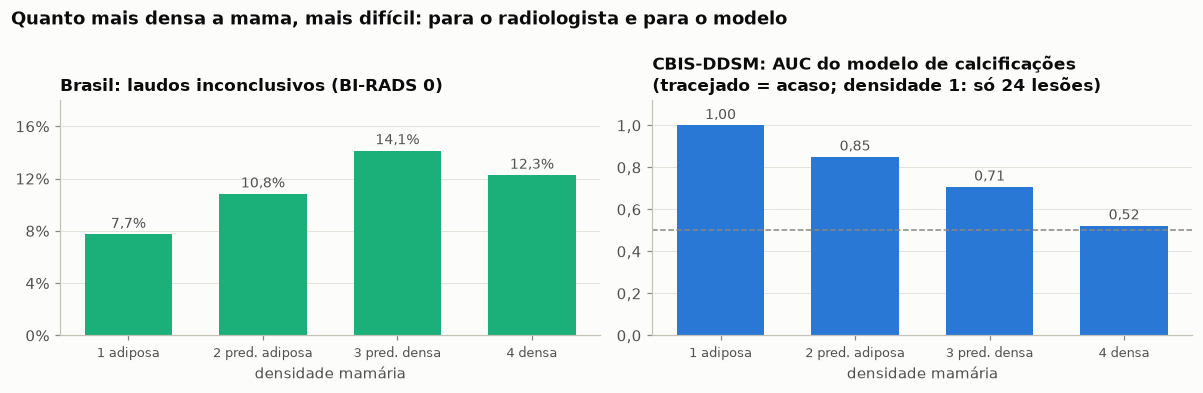

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cores_dens = estilo.SEQUENCIAL_AZUL[1:5]
barras = axes[0].bar(dificuldade.index, dificuldade["Brasil: % BI-RADS 0"], color=VERDE_AGUA, width=0.65)
axes[0].bar_label(barras, labels=[f"{v:.1f}%".replace(".", ",") for v in dificuldade["Brasil: % BI-RADS 0"]],
                  padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
axes[0].set_ylim(0, 18)
axes[0].yaxis.set_major_locator(mticker.MultipleLocator(4))
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[0].set_title("Brasil: laudos inconclusivos (BI-RADS 0)", fontsize=11)

barras = axes[1].bar(dificuldade.index, dificuldade["CBIS: AUC do modelo"], color=AZUL, width=0.65)
axes[1].bar_label(barras, labels=[f"{v:.2f}".replace(".", ",") for v in dificuldade["CBIS: AUC do modelo"]],
                  padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
axes[1].axhline(0.5, color=estilo.TINTA_SUAVE, ls="--", lw=1)
axes[1].set_ylim(0, 1.12)
axes[1].yaxis.set_major_locator(mticker.MultipleLocator(0.2))
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
axes[1].set_title("CBIS-DDSM: AUC do modelo de calcificações\n(tracejado = acaso; densidade 1: só 24 lesões)", fontsize=11)
for ax in axes:
    ax.tick_params(axis="x", labelsize=8.5)
    ax.set_xlabel("densidade mamária")
fig.suptitle("Quanto mais densa a mama, mais difícil: para o radiologista e para o modelo",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "18_densidade_dificuldade")

## 4. O desempenho do modelo na composição brasileira

O conjunto de teste do CBIS-DDSM tem uma mistura própria de densidades. Para estimar o desempenho com a mistura de
outra população, cada lesão recebe um **peso** igual a (proporção da sua densidade na população-alvo) ÷
(proporção no teste). Depois calculamos a **AUC ponderada**. Populações-alvo:

- Brasil, todas as idades;
- Brasil, por faixa etária: 40–49, 50–69 (faixa-alvo do rastreamento) e 70 ou mais.

**Suposição:** dentro de cada categoria de densidade, o modelo erra igual no CBIS-DDSM e no Brasil. A reponderação
corrige só a **mistura** de densidades, não diferenças de equipamento, população ou prevalência. Os intervalos vêm
de bootstrap (o teste tem 326 lesões).

In [10]:
def dist_faixas(faixas):
    t = tab_fx.loc[[f for f in tab_fx.index if rotulo_faixa(f) in faixas]].sum()
    return t / t.sum()

alvos = {
    "CBIS-DDSM (teste, sem peso)": None,
    "Brasil, todas as idades": br_dens / 100,
    "Brasil, 40–49": dist_faixas(["40–44", "45–49"]),
    "Brasil, 50–69": dist_faixas(["50–54", "55–59", "60–64", "65–69"]),
    "Brasil, 70+": dist_faixas(["70–74", "75–79", "80+"]),
}

base = pred.dropna(subset=["breast_density"]).copy()
p_teste = base["breast_density"].value_counts(normalize=True)

def pesos(alvo, df):
    if alvo is None:
        return np.ones(len(df))
    return df["breast_density"].map(alvo / p_teste).to_numpy()

rng = np.random.default_rng(0)
linhas = []
for nome, alvo in alvos.items():
    auc = roc_auc_score(base["maligno"], base["prob"], sample_weight=pesos(alvo, base))
    boot = []
    for _ in range(1000):
        b = base.iloc[rng.integers(0, len(base), len(base))]
        boot.append(roc_auc_score(b["maligno"], b["prob"], sample_weight=pesos(alvo, b)))
    dens_alvo = (alvo if alvo is not None else p_teste).reindex(DENS)
    linhas.append({"população": nome, "AUC": auc, "IC95% inf": np.percentile(boot, 2.5),
                   "IC95% sup": np.percentile(boot, 97.5), "% densas (3+4)": 100 * dens_alvo[[3, 4]].sum()})
reponderado = pd.DataFrame(linhas).set_index("população")

# sensibilidade: sem a densidade 1 (24 lesões, AUC = 1,00, pesos grandes nas faixas mais velhas)
sem1 = base[base["breast_density"] != 1]
p_teste_sem1 = sem1["breast_density"].value_counts(normalize=True)
def auc_sem1(alvo):
    if alvo is None:
        return roc_auc_score(sem1["maligno"], sem1["prob"])
    a = alvo.reindex([2, 3, 4]) / alvo.reindex([2, 3, 4]).sum()
    return roc_auc_score(sem1["maligno"], sem1["prob"], sample_weight=sem1["breast_density"].map(a / p_teste_sem1))
reponderado["AUC sem densidade 1"] = [auc_sem1(a) for a in alvos.values()]
reponderado

,AUC,IC95% inf,IC95% sup,% densas (3+4),AUC sem densidade 1
população,,,,,
"CBIS-DDSM (teste, sem peso)",0.74,0.68,0.79,57.10,0.72
"Brasil, todas as idades",0.76,0.71,0.82,50.21,0.73
"Brasil, 40–49",0.73,0.67,0.78,65.50,0.70
"Brasil, 50–69",0.78,0.72,0.83,44.23,0.74
"Brasil, 70+",0.81,0.75,0.86,33.41,0.76


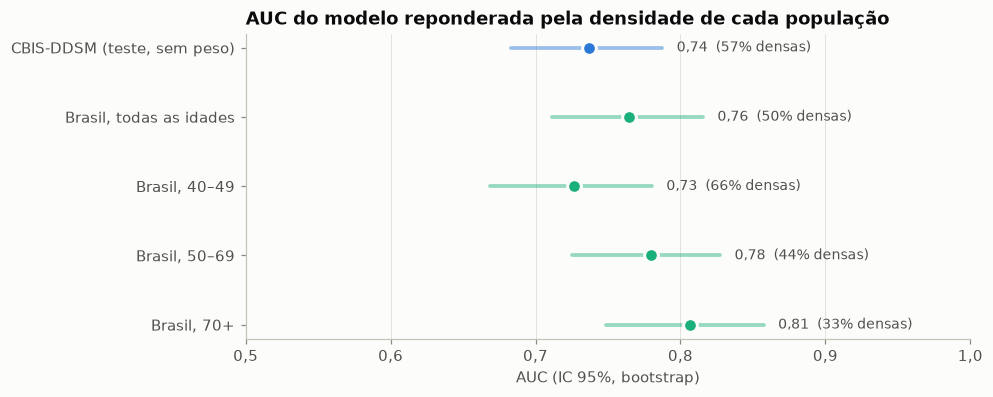

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
y = np.arange(len(reponderado))[::-1]
cores = [AZUL] + [VERDE_AGUA] * (len(reponderado) - 1)
for yi, (nome, r), cor in zip(y, reponderado.iterrows(), cores):
    ax.plot([r["IC95% inf"], r["IC95% sup"]], [yi, yi], color=cor, lw=2.5, alpha=0.45, solid_capstyle="round")
    ax.plot(r["AUC"], yi, "o", color=cor, markersize=9, markeredgecolor=estilo.FUNDO, markeredgewidth=2)
    ax.text(r["IC95% sup"] + 0.01, yi, f"{r['AUC']:.2f}  ({r['% densas (3+4)']:.0f}% densas)".replace(".", ","),
            va="center", color=estilo.TINTA_SECUNDARIA, fontsize=9)
ax.set_yticks(y, reponderado.index)
ax.axvline(0.5, color=estilo.EIXO, lw=1)
ax.set_xlim(0.5, 1.0)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.set_xlabel("AUC (IC 95%, bootstrap)")
ax.set_title("AUC do modelo reponderada pela densidade de cada população")
salvar(fig, "19_auc_reponderada")

## 5. Conclusões

**1. Densidade, no total: o CBIS-DDSM é compatível com o Brasil.** Brasil 16/34/34/16% contra CBIS-DDSM
15/39/31/16% (w de Cohen = 0,10, diferença pequena). A hipótese do notebook 03, de que as brasileiras teriam mamas
mais densas, **não se confirma no agregado**. Nos subconjuntos o quadro muda: as massas do CBIS-DDSM estão em mamas
menos densas (w = 0,30) e as calcificações, em mamas mais densas (w = 0,19).

**2. A densidade é dominada pela idade, e a idade é justamente o que o CBIS-DDSM não tem.** No Brasil, 68% das
mamas são densas entre 40 e 44 anos, contra 35% entre 65 e 69. Os 46% de mamas densas do CBIS-DDSM equivalem ao
perfil de uma brasileira de **cerca de 55 anos**. Coincidir no total não garante que a base cubra bem as mulheres
jovens, que são **27% do rastreamento do SUS** (notebook 01).

**3. BI-RADS: o tipo de caso é completamente diferente.** No rastreamento do SUS, 0,9% dos laudos são suspeitos
(BI-RADS 4 ou 5) e 86% são normais ou benignos (1 ou 2). No CBIS-DDSM, **62% são suspeitos** e quase não há
BI-RADS 1. Mesmo as mamografias diagnósticas do SUS têm só 5% de suspeitos. Isso confirma, com outra fonte, a
diferença de prevalência já vista no notebook 01.

**4. Mamas densas são mais difíceis para o radiologista e para o modelo.** No Brasil, o laudo inconclusivo
(BI-RADS 0) sobe de 7,7% em mamas adiposas para 14,1% em mamas predominantemente densas. No CBIS-DDSM, a AUC do
modelo cai de 0,85 (densidade 2) para 0,52 (densidade 4).

**5. Desempenho estimado na composição brasileira.** Reponderando pela densidade:

| População | AUC | AUC sem densidade 1 |
|---|---|---|
| CBIS-DDSM (teste) | 0,74 | 0,72 |
| Brasil, todas as idades | 0,76 | 0,73 |
| Brasil, 40–49 | **0,73** | **0,70** |
| Brasil, 70+ | **0,81** | **0,76** |

No agregado, o desempenho "no Brasil" seria parecido com o medido na base. Mas ele é pior nas mulheres de 40 a
49 anos e melhor nas mais velhas. A diferença se mantém sem a densidade 1, embora menor. Os intervalos de
confiança se sobrepõem, então a direção do efeito é mais robusta do que o tamanho.

### Resposta à pergunta do trabalho

> *Em que medida as características dos casos do CBIS-DDSM são compatíveis com o perfil epidemiológico do câncer de
> mama no Brasil?*

- **Densidade mamária:** compatível no agregado.
- **Composição dos casos (BI-RADS e prevalência de câncer):** incompatível. O CBIS-DDSM é um conjunto de lesões
  suspeitas, não uma amostra de mulheres rastreadas. Métricas como VPP e taxa de falsos positivos não se
  transferem.
- **Idade:** impossível verificar. Como a idade determina a densidade, e a densidade determina o desempenho, essa
  ausência esconde exatamente o subgrupo em que o modelo vai pior: as mulheres mais jovens, com mamas mais densas.

O risco principal não está em "o CBIS-DDSM ser diferente do Brasil na média". Está em a média esconder diferenças
entre subgrupos que a base não permite identificar.

### Limitações

- O SISCAN cobre cerca de 70% das mamografias do SUS (3,0 milhões contra 4,25 milhões no SIA em 2022), e a adesão
  varia entre estados. A unidade é o exame, não a mulher.
- A densidade do Brasil é a da mama direita; a esquerda é praticamente igual.
- A reponderação supõe que, **dentro de cada densidade**, o modelo erra igual no CBIS-DDSM e no Brasil. Ela não
  corrige diferenças de equipamento (o CBIS-DDSM é de filmes digitalizados dos anos 1990; o SUS usa mamógrafos
  analógicos e digitais), de população ou de prevalência.
- O conjunto de teste é pequeno (326 lesões; 24 com densidade 1).